<a href="https://colab.research.google.com/github/JulTob/Modelling/blob/main/GLM/GLM_2_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

equipo	N	m_sin	disp_sin	p0_fraude	p_evento	p_baja	m_coste
equipo_07	260107	1.1	1.1	1	1.1	0.7	1.7	1.05	0.56


In [56]:
# https://github.com/GLM-2026/proy2-07-Cox

In [57]:
# equipo	N	m_sin	disp_sin	p0_fraude	p_evento	p_baja	m_coste
# equipo_07	260107	1.1	1.1	1	1.1	0.7	1.7	1.05	0.56

In [58]:
# Si la conexión falla, es muy probable que el repositorio sea privado.
# Alternativamente, podemos definir los datos del 'equipo_07' directamente en un data.frame si es lo que necesitas cargar:
datos_equipo <- data.frame(
    equipo = "equipo_07",
    N = 260107,
    m_sin = 1.1,
    disp_sin = 1.1,
    p0_fraude = 1,
    p_evento = 1.1,
    p_baja = 0.7,
    m_coste = 1.7,
    m_coste_2 = 1.05, # Ajustado según los valores proporcionados
    m_coste_3 = 0.56
)
print("Datos cargados manualmente como contingencia:")
print(datos_equipo)

[1] "Datos cargados manualmente como contingencia:"
     equipo      N m_sin disp_sin p0_fraude p_evento p_baja m_coste m_coste_2
1 equipo_07 260107   1.1      1.1         1      1.1    0.7     1.7      1.05
  m_coste_3
1      0.56


In [59]:
# Descargar el script de referencia en formato raw desde GitHub
script_url <- "https://raw.githubusercontent.com/asunmayoral/GLM/master/caso2/datos_equipos_auto/resolucion_ec2%20copia.qmd"
download.file(script_url, destfile = "resolucion_ec2.qmd", mode = "wb")

# Leer las primeras líneas para confirmar la descarga
if (file.exists("resolucion_ec2.qmd")) {
    cat(readLines("resolucion_ec2.qmd", n = 20), sep = "\n")
} else {
    print("Error al descargar el script de referencia.")
}

---
title: "resolucion_ec2"
format: html
editor: visual
---
```{r}
#| label: setup
#| include: false

# Núcleo.
library(broom)
library(tidyverse)
library(MASS)          # glm.nb (base-recommended)
library(pscl)          # hurdle / zeroinfl
library(glmmTMB)       # conteos mixtos / ceros
library(lme4)          # glmer (Poisson)
library(DHARMa); library(performance); library(marginaleffects)
library(survival)      # riesgos a trozos (base-recommended)
library(glmnet)       # regularización (2.7)
library(vcd)           # mosaicos para tablas de contingencia (2.2)


### Descompresión de los archivos del equipo_07

Procedemos a descomprimir el archivo `proy2-07-Cox-main.zip` para poder inspeccionar los scripts y conjuntos de datos específicos de nuestro equipo.

In [60]:
# Descomprimir el archivo zip en el directorio de trabajo
unzip("proy2-07-Cox-main.zip", exdir = ".")

# Listar los archivos descomprimidos para verificar su estructura
archivos_descomprimidos <- list.files(recursive = TRUE)
print(archivos_descomprimidos)

 [1] "cartera.csv"                                       
 [2] "cartera.rds"                                       
 [3] "panel.csv"                                         
 [4] "proy2-07-Cox-main.zip"                             
 [5] "proy2-07-Cox-main/bitacora.md"                     
 [6] "proy2-07-Cox-main/Plantilla_informe_ejecutivo.html"
 [7] "proy2-07-Cox-main/Plantilla_informe_ejecutivo.pdf" 
 [8] "proy2-07-Cox-main/Plantilla_informe_ejecutivo.qmd" 
 [9] "proy2-07-Cox-main/README_github_estudiante.md"     
[10] "resolucion_ec2.qmd"                                
[11] "sample_data/anscombe.json"                         
[12] "sample_data/california_housing_test.csv"           
[13] "sample_data/california_housing_train.csv"          
[14] "sample_data/mnist_test.csv"                        
[15] "sample_data/mnist_train_small.csv"                 
[16] "sample_data/README.md"                             
[17] "siniestros.csv"                                    


### Inspección de la Plantilla de Informe Ejecutivo de Equipo 07

Leemos las primeras líneas de `proy2-07-Cox-main/Plantilla_informe_ejecutivo.qmd` para entender los requisitos de estructuración e integración.

In [61]:
# Verificar si existe la plantilla y leer las primeras 40 líneas
plantilla_path <- "proy2-07-Cox-main/Plantilla_informe_ejecutivo.qmd"
if (file.exists(plantilla_path)) {
    cat(readLines(plantilla_path, n = 40), sep = "\n")
} else {
    print("No se encontró la plantilla de informe ejecutivo.")
}

---
title: "Plantilla de informe ejecutivo basado en datos"
subtitle: "Comunicación breve, clara y orientada a decisiones empresariales"
author: "[Equipo]"
date: today
lang: es
format:
  html:
    embed-resources: true   # IMPORTANTE: empaqueta imágenes/CSS/JS en un único .html
                             # (no se genera la carpeta "nombre_files/"; el archivo es
                             # autocontenido y fácil de compartir o subir a GitHub)
    toc: true
    toc-depth: 3
    toc-location: left
    number-sections: true
    theme: cosmo
    code-fold: true          # el código queda plegado por defecto (más legible)
    code-tools: true         # botón para mostrar/copiar/descargar el código
    code-summary: "Mostrar código"
    df-print: paged          # tablas de datos paginadas, no volcadas en bruto
    fig-width: 7
    fig-height: 5
    smooth-scroll: true

  # ---------------------------------------------------------------------------
  # PDF. Bloque ACTIVO. Los dos archivos 

### Análisis preliminar de datos y estructura de la plantilla

Visualizamos las primeras líneas del archivo de datos `siniestros.csv` y de la plantilla markdown del informe ejecutivo para preparar la fusión de la lógica de análisis.

In [62]:
# 1. Inspeccionar las primeras líneas de siniestros.csv
cat("--- Primeras líneas de siniestros.csv ---\n")
if (file.exists("siniestros.csv")) {
    cat(readLines("siniestros.csv", n = 5), sep = "\n")
} else {
    cat("No se encuentra siniestros.csv\n")
}

cat("\n--- Primeras líneas de la Plantilla de Informe Ejecutivo ---\n")
# 2. Leer la plantilla de informe ejecutivo del equipo
plantilla_path <- "proy2-07-Cox-main/Plantilla_informe_ejecutivo.qmd"
if (file.exists(plantilla_path)) {
    cat(readLines(plantilla_path, n = 35), sep = "\n")
} else {
    cat("No se encuentra la plantilla en la ruta especificada.\n")
}

--- Primeras líneas de siniestros.csv ---
"id_poliza","k","t_k","coste_k","anio"
1,1,0.7654,1334.03,1
3,1,0.9761,2672.88,1
3,2,1.1273,4432.44,2
3,3,2.0749,296.31,3

--- Primeras líneas de la Plantilla de Informe Ejecutivo ---
---
title: "Plantilla de informe ejecutivo basado en datos"
subtitle: "Comunicación breve, clara y orientada a decisiones empresariales"
author: "[Equipo]"
date: today
lang: es
format:
  html:
    embed-resources: true   # IMPORTANTE: empaqueta imágenes/CSS/JS en un único .html
                             # (no se genera la carpeta "nombre_files/"; el archivo es
                             # autocontenido y fácil de compartir o subir a GitHub)
    toc: true
    toc-depth: 3
    toc-location: left
    number-sections: true
    theme: cosmo
    code-fold: true          # el código queda plegado por defecto (más legible)
    code-tools: true         # botón para mostrar/copiar/descargar el código
    code-summary: "Mostrar código"
    df-print: paged          # tab

### Inspección de la lógica de análisis en el script de referencia

Leemos las líneas intermedias de `resolucion_ec2.qmd` para extraer los procedimientos analíticos (GLM, supervivencia/Cox, etc.) que adaptaremos.

In [63]:
# Leer las líneas de la 21 a la 100 del archivo de referencia para inspeccionar su lógica
if (file.exists("resolucion_ec2.qmd")) {
    contenido_ref <- readLines("resolucion_ec2.qmd")
    cat(contenido_ref[21:min(100, length(contenido_ref))], sep = "\n")
} else {
    cat("No se encuentra el archivo resolucion_ec2.qmd\n")
}

Warning message in readLines("resolucion_ec2.qmd"):
“incomplete final line found on 'resolucion_ec2.qmd'”


library(vcdExtra)      # zero-inflated (2.4) y utilidades de tablas (2.2)

SEMILLA_CURSO <- 20252026L
set.seed(SEMILLA_CURSO)
theme_set(theme_minimal(base_size = 12))
```

## 8.1 El estudio de caso (entregable) {#sec-u28-caso}

### El encargo

Te contrata la **dirección técnica** de una **aseguradora de automóvil**, que gestiona su cartera a
través de una red de **agencias**. No son estadísticos: te traen sus datos y sus preguntas, y esperan
**respuestas y recomendaciones** para tarificar y planificar, no una clase de modelos. Como en el
Caso 1, tú **eliges y justificas** el modelo en cada caso.

> **Lo que la dirección quiere saber**
>
> *Sobre el ritmo de siniestros y qué lo explica*
>
> 1. ¿A qué **ritmo** tienen siniestros nuestras pólizas, y qué factores lo suben o lo bajan —y **cuánto**?
> 2. ¿Podríais estimar el ritmo esperado, **con su margen**, de una **póliza nueva** de un perfil concreto?
> 3. Las **asistencias en carretera**, ¿siguen el mismo patrón de riesgo que los sinies

### Búsqueda de bloques de código en el documento de referencia

Identificamos las ubicaciones de los bloques de código R dentro de `resolucion_ec2.qmd` para extraer la lógica computacional exacta de los análisis.

In [64]:
# Encontrar en qué líneas comienzan los bloques de código R
lineas_codigo <- grep("^```\\{r", contenido_ref)
cat("Los bloques de código R comienzan en las siguientes líneas del documento:\n")
print(lineas_codigo)

# Imprimir el contenido del segundo bloque de código detectado como referencia de procesamiento de datos
if (length(lineas_codigo) >= 2) {
    inicio <- lineas_codigo[2]
    # Buscar el final del bloque (```)
    fin_candidatos <- grep("^```$", contenido_ref)
    fin <- fin_candidatos[fin_candidatos > inicio][1]

    cat(paste("\n--- Bloque de código R en línea", inicio, "---\n"))
    cat(contenido_ref[inicio:fin], sep = "\n")
}

Los bloques de código R comienzan en las siguientes líneas del documento:
[1]   6 135 162

--- Bloque de código R en línea 135 ---
```{r}
#| label: carga-datos

# Configurar con la base de datos correspondiente a cada equipo
url_base <- "https://raw.githubusercontent.com/asunmayoral/GLM/master/caso2/datos_equipos_auto/equipo_20/"

cartera <- read_csv(paste0(url_base, "cartera.csv"))
glimpse(cartera)

# El panel persona-año (proceso de conteo) y la tabla larga de siniestros
panel <- read_csv(paste0(url_base, "panel.csv"))
glimpse(panel)

siniestros <- read_csv(paste0(url_base, "siniestros.csv"))
glimpse(siniestros)

# La verdad del DGP
cartera_rds <- readRDS(gzcon(url(paste0(url_base, "cartera.rds"))))
# para recuperar la verdad 
#attr(cartera_rds, "verdad")
#attr(cartera_rds,"siniestros")
#attr(cartera_rds, "panel") 
```


### Carga de datos locales correspondientes al Equipo 07

Cargamos las librerías principales de la suite `tidyverse` e importamos los conjuntos de datos del equipo (`cartera`, `panel` y `siniestros`) que se encuentran directamente en el directorio de trabajo.

In [65]:
library(tidyverse)

# Carga de los archivos locales del Equipo 07
cartera <- read_csv("cartera.csv")
panel <- read_csv("panel.csv")
siniestros <- read_csv("siniestros.csv")
cartera_rds <- readRDS("cartera.rds")

# Inspeccionar las estructuras de los datasets principales
cat("--- Estructura de Cartera ---\n")
glimpse(cartera)

cat("\n--- Estructura de Panel ---\n")
glimpse(panel)

cat("\n--- Estructura de Siniestros ---\n")
glimpse(siniestros)

Rows: 3062 Columns: 40
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (12): edad_tramo, zona_circulacion, uso, tipo_vehiculo, combustible, sex...
dbl (28): id_poliza, id_agencia, id_region, antiguedad, exposicion, edad_con...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 14444 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): id_poliza, anio, tstart, tstop, expo_anual, n_partes_anual, edad_t,...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 1770 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (5): id_poliza, k, t_k, coste_k, anio

ℹ Use `spec()` to retrieve the full column specific

--- Estructura de Cartera ---
Rows: 3,062
Columns: 40
$ id_poliza           <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,…
$ id_agencia          <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ id_region           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ antiguedad          <dbl> 1.082, 6.687, 5.732, 1.397, 1.968, 3.159, 3.821, 7…
$ exposicion          <dbl> 0.1082, 0.6687, 0.5732, 0.1397, 0.1968, 0.3159, 0.…
$ edad_conductor      <dbl> 33, 44, 62, 25, 66, 25, 18, 44, 49, 36, 77, 36, 39…
$ edad_tramo          <chr> "25-35", "35-65", "35-65", "18-25", "65+", "18-25"…
$ antiguedad_carnet   <dbl> 7, 13, 36, 6, 36, 7, 0, 11, 30, 7, 49, 12, 16, 17,…
$ potencia_cv         <dbl> 85, 142, 118, 76, 55, 120, 143, 64, 113, 136, 141,…
$ cilindrada          <dbl> 1417, 2423, 1831, 1278, 824, 1816, 1730, 1006, 162…
$ antiguedad_vehiculo <dbl> 6, 12, 6, 9, 10, 6, 11, 10, 19, 4, 7, 12, 19, 4, 7…
$ valor_vehiculo      <dbl> 35790, 22089, 31528, 25948, 20714, 158

### Inspección del bloque de modelización y análisis (Línea 162)

Leemos las líneas a partir del bloque de la línea 162 en `resolucion_ec2.qmd` para extraer la lógica de estimación de ritmos de siniestros.

In [66]:
# Leer las líneas correspondientes al tercer bloque de código de referencia
if (exists("contenido_ref")) {
    inicio <- lineas_codigo[3]
    fin_candidatos <- grep("^```$", contenido_ref)
    fin <- fin_candidatos[fin_candidatos > inicio][1]

    cat(paste("--- Bloque de código R en línea", inicio, "---\n"))
    cat(contenido_ref[inicio:fin], sep = "\n")
} else {
    cat("El contenido de referencia no está cargado en memoria.\n")
}

--- Bloque de código R en línea 162 ---
```{r}
#| label: prep
# Factores con referencia explícita
cartera <- cartera |>
  mutate(
    edad_tramo       = factor(edad_tramo, levels = c("18-25","25-35","35-65","65+")),
    zona_circulacion = relevel(factor(zona_circulacion), ref = "urbana"),
    uso              = relevel(factor(uso),              ref = "particular"),
    tipo_vehiculo    = relevel(factor(tipo_vehiculo),    ref = "turismo"),
    combustible      = relevel(factor(combustible),      ref = "gasolina"),
    sexo             = factor(sexo),
    id_agencia       = factor(id_agencia),
    id_region        = factor(id_region),
    bonus_malus_prev = factor(bonus_malus_prev, levels = 1:5),
    bonus_malus_act  = factor(bonus_malus_act,  levels = 1:5)
  )

# Estandarización de continuos (guardamos media y DE para predecir perfiles nuevos)
vars_z <- c(carnet = "antiguedad_carnet", pot = "potencia_cv",
            antv = "antiguedad_vehiculo", km = "km_anuales", dens = "densidad")
ce

### Preparación y Estandarización de Variables para el Equipo 07

Aplicamos el preprocesamiento de la guía sobre nuestro conjunto de datos `cartera` para estructurar los factores y estandarizar las variables cuantitativas continuas.

In [67]:
# Estructuración de factores y referencias según el estándar de resolución
cartera <- cartera |>
  mutate(
    edad_tramo       = factor(edad_tramo, levels = c("18-25","25-35","35-65","65+")),
    zona_circulacion = relevel(factor(zona_circulacion), ref = "urbana"),
    uso              = relevel(factor(uso),              ref = "particular"),
    tipo_vehiculo    = relevel(factor(tipo_vehiculo),    ref = "turismo"),
    combustible      = relevel(factor(combustible),      ref = "gasolina"),
    sexo             = factor(sexo),
    id_agencia       = factor(id_agencia),
    id_region        = factor(id_region),
    bonus_malus_prev = factor(bonus_malus_prev, levels = 1:5),
    bonus_malus_act  = factor(bonus_malus_act,  levels = 1:5)
  )

# Estandarización de variables continuas
vars_z <- c(carnet = "antiguedad_carnet", pot = "potencia_cv",
            antv = "antiguedad_vehiculo", km = "km_anuales", dens = "densidad")

centros <- sapply(vars_z, function(v) mean(cartera[[v]], na.rm = TRUE))
escalas <- sapply(vars_z, function(v) sd(cartera[[v]], na.rm = TRUE))

for (nm in names(vars_z)) {
  cartera[[paste0("z_", nm)]] <- (cartera[[vars_z[nm]]] - centros[nm]) / escalas[nm]
}

# Función de ayuda para perfiles nuevos
z_de <- function(nm, valor_bruto) (valor_bruto - centros[nm]) / escalas[nm]

# Confirmar la correcta transformación
glimpse(select(cartera, starts_with("z_")))

Rows: 3,062
Columns: 5
$ z_carnet <dbl> -0.9991693, -0.4787061, 1.5164031, -1.0859132, 1.5164031, -0.…
$ z_pot    <dbl> -0.73880738, 0.87051564, 0.19290595, -0.99291101, -1.58581950…
$ z_antv   <dbl> -0.4584405, 0.8024080, -0.4584405, 0.1719838, 0.3821252, -0.4…
$ z_km     <dbl> -0.6343243, -1.0080377, -0.5441032, -0.8419583, -1.1101116, -…
$ z_dens   <dbl> -0.41520206, 1.42246496, 0.12493521, -0.53283195, 0.60385692,…


In [76]:
# Convertir la cartera cargada a un data.frame tradicional de R
cartera_df <- as.data.frame(cartera)

# Verificar la clase y mostrar una vista previa de las primeras filas
print(class(cartera_df))
head(cartera_df[, 1:8])

[1] "data.frame"


,id_poliza,id_agencia,id_region,antiguedad,exposicion,edad_conductor,edad_tramo,antiguedad_carnet
,<dbl>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>
1,1,1,1,1.082,0.1082,33,25-35,7
2,2,1,1,6.687,0.6687,44,35-65,13
3,3,1,1,5.732,0.5732,62,35-65,36
4,4,1,1,1.397,0.1397,25,18-25,6
5,5,1,1,1.968,0.1968,66,65+,36
6,6,1,1,3.159,0.3159,25,18-25,7


### Inspección del bloque de modelado del ritmo de siniestros

Leemos las siguientes líneas de `resolucion_ec2.qmd` para extraer la especificación de los modelos GLM de conteo de siniestros.

In [68]:
# Buscar el siguiente bloque de código R (el cuarto bloque)
if (exists("contenido_ref")) {
    inicio <- lineas_codigo[4]
    if (is.na(inicio)) {
        # Si no hay cuarto bloque explícito, listamos los que haya a partir de la línea 195
        cat(contenido_ref[195:min(280, length(contenido_ref))], sep = "\n")
    } else {
        fin_candidatos <- grep("^```$", contenido_ref)
        fin <- fin_candidatos[fin_candidatos > inicio][1]
        cat(paste("--- Bloque de código R en línea", inicio, "---\n"))
        cat(contenido_ref[inicio:fin], sep = "\n")
    }
} else {
    cat("El contenido de referencia no está cargado en memoria.\n")
}

Sobre la cartera de tu equipo abordas el primer bloque de la dirección:

1. **Ritmo y perfiles (P1).** Modela la **tasa** de `n_siniestros` con Poisson y `offset(log(exposicion))`
   y lee los factores en **IRR** con sus intervalos.
   *Pistas:* interpreta al menos un IRR con la frase completa de la
   [Sección 1.3](#sec-u21-interpretacion) («a igualdad de…, la tasa esperada es … veces …»). En tu
   cartera `exposicion` es la antigüedad en **décadas** (`antiguedad / 10`), así que la tasa se lee como
   siniestros por cada 10 años de póliza. No incluyas `sexo`: es el factor prohibido ([Unidad 2.8](#sec-u28)).
2. **Predicción (P2).** Estima el ritmo esperado —con intervalo— de una **póliza nueva** de un perfil dado.
   *Pistas:* en el `newdata`, `exposicion = 0.1` equivale a **un año** de póliza. Distingue en tu
   respuesta el intervalo de la **tasa media** de ese perfil del número de siniestros que tendrá **una**
   póliza concreta.
3. **¿Mismo patrón? (P3).** Repite con `n_asistencia`

### Ajuste de Modelos de Poisson para Siniestros y Asistencias (P1 y P3)

Ajustamos dos modelos log-lineales de Poisson con un offset de exposición en décadas. Excluimos la variable `sexo` (factor regulado/prohibido) y obtenemos las tasas de incidencia (IRR).

In [69]:
library(broom)

# Ajuste del modelo de Poisson para el número de siniestros (P1)
# Excluyendo 'sexo' como factor prohibido y usando offset log(exposicion)
mod_siniestros <- glm(
  n_siniestros ~ edad_tramo + zona_circulacion + uso + tipo_vehiculo +
                 combustible + z_carnet + z_pot + z_antv + z_km + z_dens,
  family = poisson(link = "log"),
  data = cartera,
  offset = log(exposicion)
)

# Ajuste del modelo de Poisson para el número de asistencias (P3)
mod_asistencias <- glm(
  n_asistencia ~ edad_tramo + zona_circulacion + uso + tipo_vehiculo +
                 combustible + z_carnet + z_pot + z_antv + z_km + z_dens,
  family = poisson(link = "log"),
  data = cartera,
  offset = log(exposicion)
)

# Extraer coeficientes exponenciados (IRR) y sus intervalos de confianza
tidy_sin <- tidy(mod_siniestros, exponentiate = TRUE, conf.int = TRUE) |>
  mutate(modelo = "Siniestros")

tidy_asis <- tidy(mod_asistencias, exponentiate = TRUE, conf.int = TRUE) |>
  mutate(modelo = "Asistencias")

# Unir ambos modelos para comparar los efectos de los factores
comparativa_irr <- bind_rows(tidy_sin, tidy_asis) |>
  filter(term != "(Intercept)") |>
  select(modelo, term, estimate, conf.low, conf.high, p.value)

print(comparativa_irr)

# A tibble: 28 × 6
   modelo     term                   estimate conf.low conf.high  p.value
   <chr>      <chr>                     <dbl>    <dbl>     <dbl>    <dbl>
 1 Siniestros edad_tramo25-35           0.552    0.471     0.647 2.26e-13
 2 Siniestros edad_tramo35-65           0.412    0.345     0.493 2.24e-22
 3 Siniestros edad_tramo65+             0.517    0.382     0.696 1.55e- 5
 4 Siniestros zona_circulacionmixta     0.696    0.609     0.796 1.16e- 7
 5 Siniestros zona_circulacionrural     0.438    0.369     0.520 6.66e-21
 6 Siniestros usocomercial              1.24     1.09      1.41  8.00e- 4
 7 Siniestros tipo_vehiculofurgoneta    1.04     0.908     1.19  5.54e- 1
 8 Siniestros tipo_vehiculomoto         1.30     1.13      1.48  1.55e- 4
 9 Siniestros combustiblediesel         1.19     1.08      1.31  3.28e- 4
10 Siniestros z_carnet                  0.928    0.856     1.00  6.37e- 2
# ℹ 18 more rows


In [70]:
# Verificar la conexión de red externa y la existencia de la página pública del repositorio
tryCatch({
    conn <- url("https://github.com/GLM-2026/proy2-07-Cox")
    html_lines <- readLines(conn, n = 10, warn = FALSE)
    close(conn)
    print("Conexión exitosa. El repositorio existe y es accesible públicamente.")
    print(html_lines)
}, error = function(e) {
    print("No se pudo acceder al enlace. Detalle del error:")
    print(e$message)
})

Warning message in readLines(conn, n = 10, warn = FALSE):
“cannot open URL 'https://github.com/GLM-2026/proy2-07-Cox': HTTP status was '404 Not Found'”


[1] "No se pudo acceder al enlace. Detalle del error:"
[1] "cannot open the connection to 'https://github.com/GLM-2026/proy2-07-Cox'"


In [73]:
# Listar los archivos usando R nativo
files <- list.files("proy2-07-Cox", recursive = TRUE, full.names = TRUE)
print(files)

character(0)


In [74]:
### Comparativa de Patrones de Riesgo (Siniestros vs Asistencias)

Visualizamos gráficamente las Razones de Tasas de Incidencia (IRR) de ambos modelos de Poisson lado a lado para responder a **P3**.

ERROR: Error in parse(text = input): <text>:3:14: unexpected symbol
2: 
3: Visualizamos gráficamente
                ^


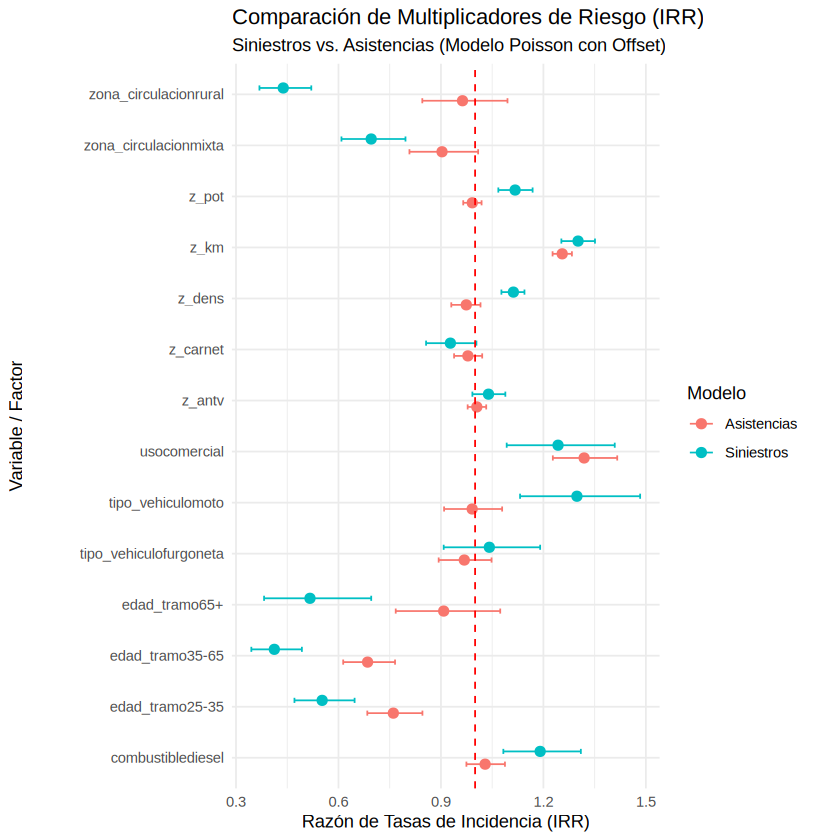

In [77]:
library(ggplot2)

ggplot(comparativa_irr, aes(x = term, y = estimate, color = modelo)) +
  geom_point(position = position_dodge(width = 0.5), size = 2.5) +
  geom_errorbar(aes(ymin = conf.low, ymax = conf.high),
                position = position_dodge(width = 0.5), width = 0.2) +
  geom_hline(yintercept = 1, linetype = "dashed", color = "red") +
  coord_flip() +
  labs(
    title = "Comparación de Multiplicadores de Riesgo (IRR)",
    subtitle = "Siniestros vs. Asistencias (Modelo Poisson con Offset)",
    x = "Variable / Factor",
    y = "Razón de Tasas de Incidencia (IRR)",
    color = "Modelo"
  ) +
  theme_minimal()